# 04 — Clean and fold

Turn every KOI's light curve into two 201-point views for the model:
- **global view**: the whole orbit
- **local view**: just the transit, ±3 transit durations

Normal brightness = 0, so a dip shows as negative values. The cleaning function is in `src/preprocess.py`, so the TESS notebook can reuse it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../src")
from preprocess import prepare_views

BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "grid.color": "#e6e5e1", "figure.dpi": 110})

DATA, RAW, RESULTS = Path("../data"), Path("../data/kepler_raw"), Path("../results")
selected = pd.read_csv(DATA / "kepler_selected.csv")

/Users/jeeyadugar/Exoplanet-Finder/.venv/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## Example: one planet, step by step

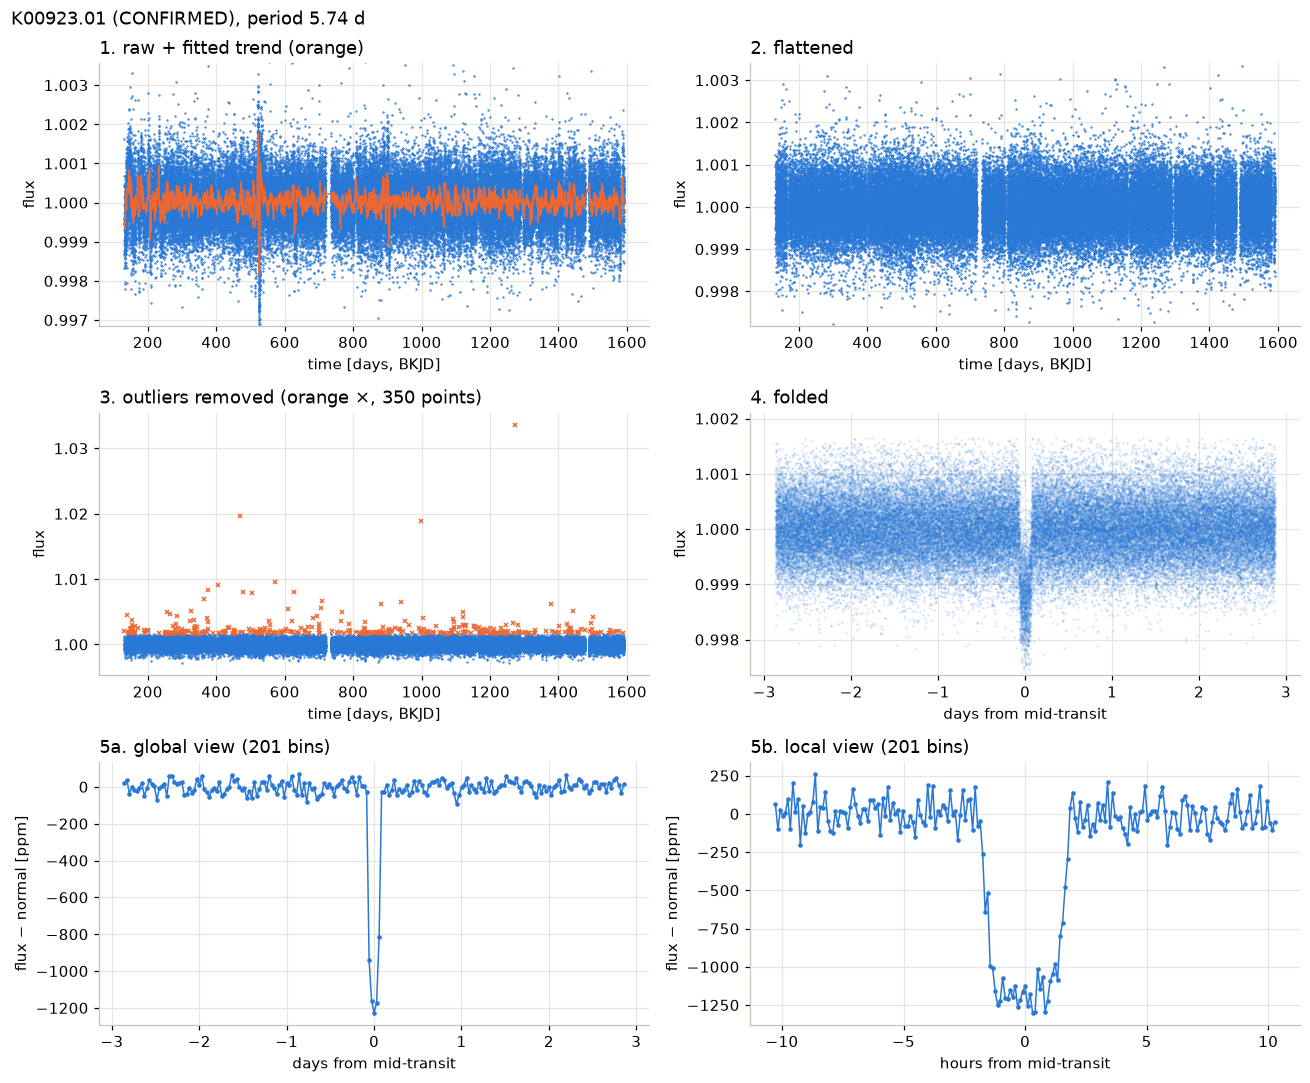

In [2]:
koi = selected[selected["kepoi_name"] == "K00923.01"].iloc[0]
raw = pd.read_csv(RAW / f"{koi.kepid}.csv")
g, l, s = prepare_views(raw.time, raw.flux, koi.koi_period, koi.koi_time0bk,
                        koi.koi_duration / 24, return_steps=True)

def zoom_y(ax, y):
    lo, hi = np.nanpercentile(y, [0.1, 99.9])
    ax.set_ylim(lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
ax = axes.flat

ax[0].plot(s["raw"].time.value, s["raw"].flux.value, ".", ms=1, color=BLUE)
ax[0].plot(s["trend"].time.value, s["trend"].flux.value, "-", lw=1, color=ORANGE)
zoom_y(ax[0], s["raw"].flux.value)
ax[0].set_title("1. raw + fitted trend (orange)", loc="left")

ax[1].plot(s["flat"].time.value, s["flat"].flux.value, ".", ms=1, color=BLUE)
zoom_y(ax[1], s["flat"].flux.value)
ax[1].set_title("2. flattened", loc="left")

ax[2].plot(s["clean"].time.value, s["clean"].flux.value, ".", ms=1, color=BLUE)
ax[2].plot(s["flat"].time.value[s["removed"]], s["flat"].flux.value[s["removed"]], "x", ms=3, color=ORANGE)
ax[2].set_title(f"3. outliers removed (orange ×, {s['removed'].sum()} points)", loc="left")

ax[3].plot(s["phase"], s["clean"].flux.value, ".", ms=1, color=BLUE, alpha=0.2)
zoom_y(ax[3], s["clean"].flux.value)
ax[3].set_title("4. folded", loc="left")

ax[4].plot(s["global_x"], g * 1e6, "o-", ms=2, lw=1, color=BLUE)
ax[4].set_title("5a. global view (201 bins)", loc="left")

ax[5].plot(s["local_x"] * 24, l * 1e6, "o-", ms=2, lw=1, color=BLUE)
ax[5].set_title("5b. local view (201 bins)", loc="left")

for a in ax[:3]: a.set_xlabel("time [days, BKJD]")
ax[3].set_xlabel("days from mid-transit"); ax[4].set_xlabel("days from mid-transit")
ax[5].set_xlabel("hours from mid-transit")
for a in ax[:4]: a.set_ylabel("flux")
for a in ax[4:]: a.set_ylabel("flux − normal [ppm]")
for a in ax: a.grid(True)
fig.suptitle(f"{koi.kepoi_name} ({koi.koi_disposition}), period {koi.koi_period:.2f} d", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(RESULTS / "clean_fold_steps.png", dpi=150)
plt.show()

## Process every KOI

In [3]:
globals_, locals_, labels, names, kepids, empty_bins = [], [], [], [], [], []
skipped, errors = [], []

for i, koi in enumerate(selected.itertuples(), start=1):
    path = RAW / f"{koi.kepid}.csv"
    if not path.exists():                      # failed download
        skipped.append(koi.kepoi_name)
        continue
    raw = pd.read_csv(path)
    try:
        g, l, s = prepare_views(raw.time, raw.flux, koi.koi_period, koi.koi_time0bk,
                                koi.koi_duration / 24, return_steps=True)
    except Exception as e:
        errors.append((koi.kepoi_name, repr(e)))
        continue
    globals_.append(g); locals_.append(l)
    labels.append(1 if koi.koi_disposition == "CONFIRMED" else 0)
    names.append(koi.kepoi_name); kepids.append(koi.kepid)
    empty_bins.append(s["local_empty_bins"])
    if i % 100 == 0:
        print(f"{i}/{len(selected)}")

print(f"\nprocessed {len(names)}, skipped {len(skipped)} (no light curve), errors {len(errors)}")
print("skipped:", skipped)
print("errors:", errors)

100/800


200/800


300/800


400/800


500/800


600/800


700/800


800/800

processed 796, skipped 4 (no light curve), errors 0
skipped: ['K00922.01', 'K03960.01', 'K06199.01', 'K08017.01']
errors: []


## Check

In [4]:
X_global = np.array(globals_, dtype=np.float32)
X_local = np.array(locals_, dtype=np.float32)
y = np.array(labels, dtype=np.int8)
empty_bins = np.array(empty_bins)

print("global:", X_global.shape, " local:", X_local.shape, " y:", y.shape)
print("planets:", (y == 1).sum(), " false positives:", (y == 0).sum())
print("any NaN:", np.isnan(X_global).any() or np.isnan(X_local).any())
mostly = empty_bins > 100
print(f"mostly interpolated local views: {mostly.sum()} "
      f"({(y[mostly] == 1).sum()} planets, {(y[mostly] == 0).sum()} false positives)")

global: (796, 201)  local: (796, 201)  y: (796,)
planets: 399  false positives: 397
any NaN: False
local views with >50% empty bins (filled by interpolation): 17


## Save

In [5]:
np.save(DATA / "kepler_global.npy", X_global)
np.save(DATA / "kepler_local.npy", X_local)
np.save(DATA / "kepler_y.npy", y)
pd.DataFrame({
    "kepoi_name": names, "kepid": kepids, "label": y,
    "mostly_interpolated": empty_bins > 100,   # >50% of local bins filled in
}).to_csv(DATA / "kepler_names.csv", index=False)
print("saved")

saved


## Local views: planets vs false positives

Each panel has its own y-scale, because depths differ a lot between signals.

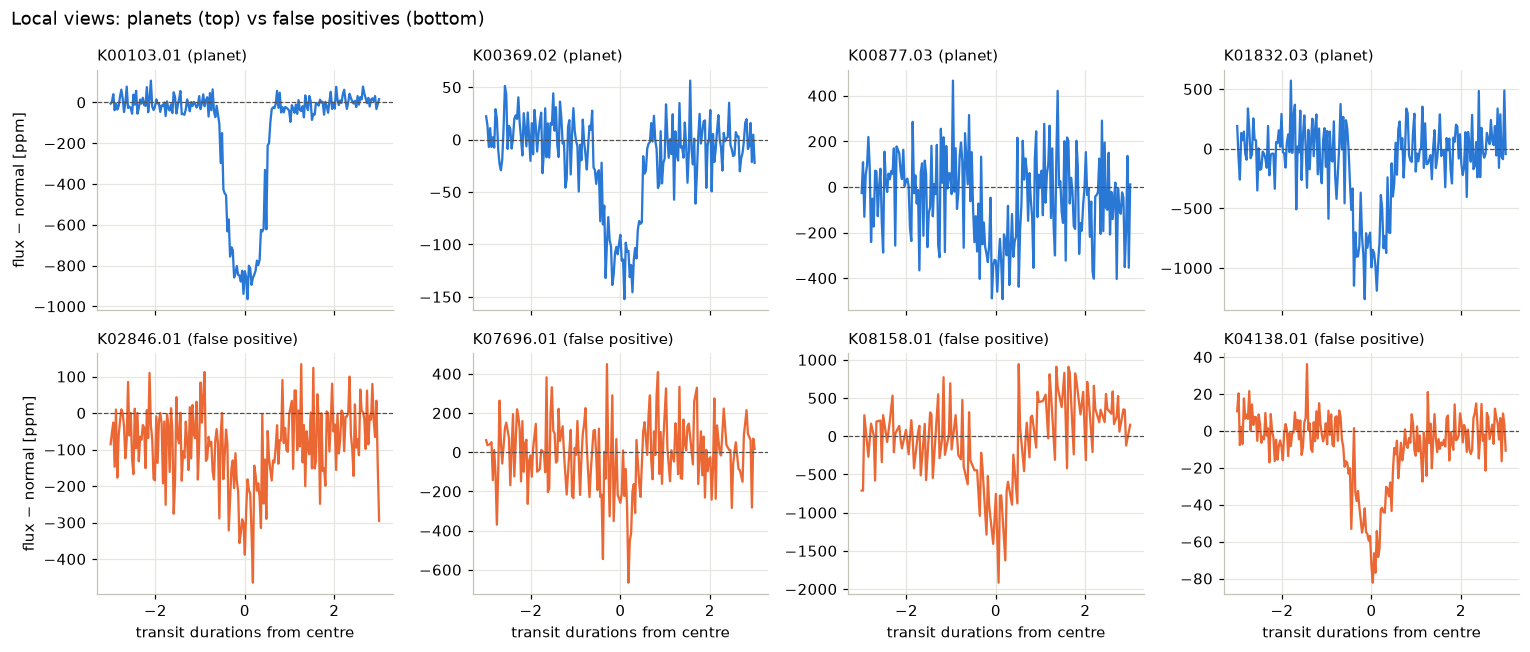

In [6]:
rng = np.random.default_rng(42)
pick_p = rng.choice(np.flatnonzero(y == 1), 4, replace=False)
pick_f = rng.choice(np.flatnonzero(y == 0), 4, replace=False)
x_local = np.linspace(-3, 3, 201)   # in transit durations

fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for row, (picks, colour, label) in enumerate([(pick_p, BLUE, "planet"), (pick_f, ORANGE, "false positive")]):
    for ax, i in zip(axes[row], picks):
        ax.plot(x_local, X_local[i] * 1e6, "-", lw=1.5, color=colour)
        ax.axhline(0, color=INK, lw=0.8, ls="--")
        ax.set_title(f"{names[i]} ({label})", loc="left", fontsize=10)
        ax.grid(True)
    axes[row, 0].set_ylabel("flux − normal [ppm]")
for ax in axes[1]: ax.set_xlabel("transit durations from centre")
fig.suptitle("Local views: planets (top) vs false positives (bottom)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(RESULTS / "local_views_examples.png", dpi=150)
plt.show()